# **AutoEncoder for Image Denoising**

## **steps**
- Read images
- Normalization
- Add noise
- Build AutoEncoder
- Train model
- Evaluate results



## **Imports**

In [5]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Models
from tensorflow.keras.applications import VGG16, MobileNet

# Layers
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, UpSampling2D,
    GlobalAveragePooling2D, Flatten, Dense, Dropout
)

# Models API
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras import layers, models

# Optimizers
from tensorflow.keras.optimizers import Adam, SGD

## **Upload dataset from kaggle**

In [6]:
!kaggle datasets download -d meowmeowmeowmeowmeow/gtsrb-german-traffic-sign

Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
License(s): CC0-1.0
100% 612M/612M [00:38<00:00, 16.5MB/s]



In [7]:
import zipfile
import os

IMG_SIZE = (32, 32)
BATCH_SIZE = 32

zip_path = "/content/gtsrb-german-traffic-sign.zip"
extract_path = "/content/gtsrb"

# -------- UNZIP --------
if not os.path.exists(extract_path):
  with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

raw_train = tf.keras.utils.image_dataset_from_directory(
    f"{extract_path}/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.3,
    subset="training",
    seed=123
)

temp_ds  = tf.keras.utils.image_dataset_from_directory(
    f"{extract_path}/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.3,
    subset="validation",
    seed=123
)

num_classes = len(raw_train.class_names)

Found 39209 files belonging to 43 classes.
Using 27447 files for training.
Found 39209 files belonging to 43 classes.
Using 11762 files for validation.


In [8]:
def add_noise(image):
    noise = 0.1 * tf.random.normal(tf.shape(image))
    noisy = image + noise
    return tf.clip_by_value(noisy, 0.0, 1.0)

def preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    noisy = add_noise(image)
    return noisy, image

def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [9]:
val_batches = tf.data.experimental.cardinality(temp_ds).numpy()

raw_val = temp_ds.take(val_batches // 2)
raw_test = temp_ds.skip(val_batches // 2)

In [10]:
AE_Train = raw_train.map(preprocess)
AE_val   = raw_val.map(preprocess)
AE_test = raw_test.map(preprocess)

CNN_Train = raw_train.map(normalize).shuffle(1000)
CNN_val   = raw_val.map(normalize)
CNN_test  = raw_test.map(normalize)

## **Bulid** **AutoEncoder**


In [11]:
input_img = layers.Input(shape=(32,32,3))

# Encoder

layer = layers.Conv2D(32 ,(3,3),activation='relu' , padding='same')(input_img)
layer = layers.Conv2D(32 ,(3,3),activation='relu' , padding='same')(layer)
layer = layers.MaxPooling2D((2,2) , padding='same')(layer)
layer =  layers.Conv2D(64 ,(3,3),activation='relu' , padding='same')(layer)
layer = layers.Conv2D(32 ,(3,3),activation='relu' , padding='same')(layer)
encoded = layers.MaxPooling2D((2,2) , padding='same')(layer)

# Decoder

layer = layers.Conv2D(64 ,(3,3),activation='relu' , padding='same')(encoded)
layer = layers.UpSampling2D((2,2))(layer)
layer = layers.Conv2D(32 ,(3,3),activation='relu' , padding='same')(layer)
layer = layers.UpSampling2D((2,2))(layer)
decoded = layers.Conv2D(3,(3,3),activation='sigmoid' , padding='same')(layer)

autoencoder = Model(input_img,decoded)

In [12]:
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)
history = autoencoder.fit(
    AE_Train,
    validation_data=AE_val,
    epochs=20
)

Epoch 1/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - loss: 0.0100 - val_loss: 0.0055
Epoch 2/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - loss: 0.0050 - val_loss: 0.0045
Epoch 3/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 0.0043 - val_loss: 0.0045
Epoch 4/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - loss: 0.0038 - val_loss: 0.0037
Epoch 5/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - loss: 0.0035 - val_loss: 0.0034
Epoch 6/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 0.0033 - val_loss: 0.0031
Epoch 7/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 0.0031 - val_loss: 0.0030
Epoch 8/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0030 - val_loss: 0.0031
Epoch 9/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 0.0029 - val_loss: 0.0029
Epoch 10/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 0.0028 - val_loss: 0.0027
Epoch 11/20
858/858 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 0.0027 - val_loss: 0.0026
Epoch 12/20
858/858 ━━━━━━━━━━

In [13]:
noisy_batch, clean_batch = next(iter(AE_test))
preds = autoencoder.predict(noisy_batch)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 520ms/step


In [14]:
ssim_scores = []
psnr_scores = []

for i in range(len(clean_batch)):
    ssim = tf.image.ssim(clean_batch[i], preds[i], max_val=1.0)
    psnr = tf.image.psnr(clean_batch[i], preds[i], max_val=1.0)

    ssim_scores.append(ssim.numpy())
    psnr_scores.append(psnr.numpy())

print("Average SSIM:", np.mean(ssim_scores))
print("Average PSNR:", np.mean(psnr_scores))

Average SSIM: 0.8525755
Average PSNR: 28.203178


### **Visualization**

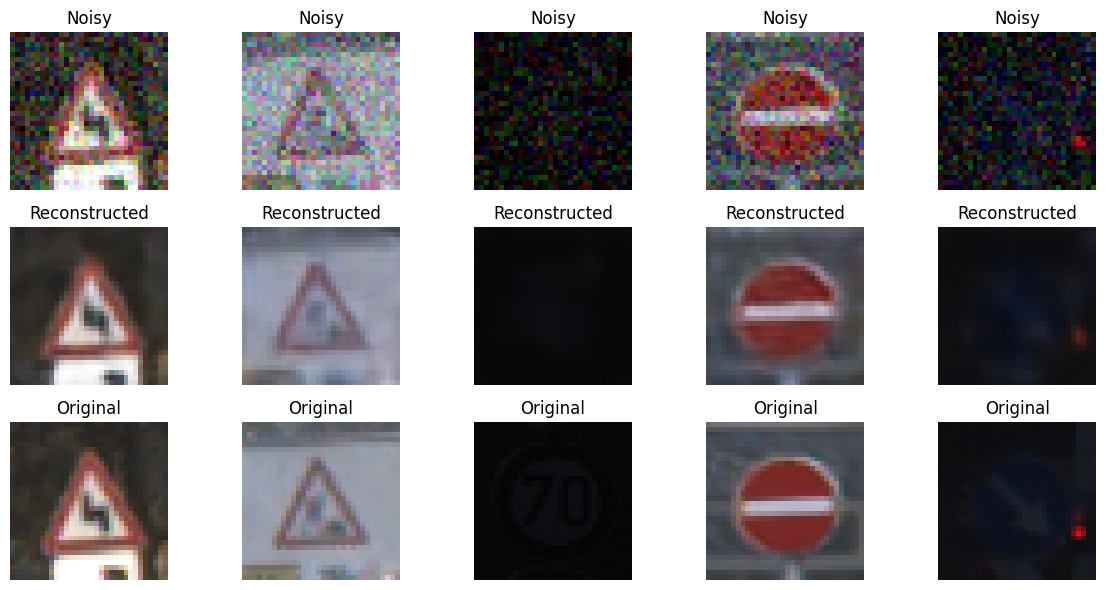

In [15]:
n = 5
plt.figure(figsize=(12,6))

for i in range(n):

    # Noisy
    plt.subplot(3, n, i+1)
    plt.imshow(noisy_batch[i])
    plt.title("Noisy")
    plt.axis("off")

    # Predicted
    plt.subplot(3, n, i+1+n)
    plt.imshow(preds[i])
    plt.title("Reconstructed")
    plt.axis("off")

    # Original
    plt.subplot(3, n, i+1+2*n)
    plt.imshow(clean_batch[i])
    plt.title("Original")
    plt.axis("off")

plt.tight_layout()
plt.show()

## **CNN Model**

In [16]:
def create_model():
    model = Sequential([
        Input(shape=(32,32,3)),

        Conv2D(32, (3,3), activation='relu', padding='same'),
        MaxPooling2D(2,2),

        Conv2D(64, (3,3), activation='relu', padding='same'),
        MaxPooling2D(2,2),

        Conv2D(128, (3,3), activation='relu', padding='same'),
        MaxPooling2D(2,2),

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),

        Dense(num_classes, activation='softmax')
    ])
    return model

In [17]:
def build_reconstructed_dataset(ds):
    images_list = []
    labels_list = []

    for images, labels in ds:
        preds = autoencoder.predict(images)  # reconstruct
        images_list.append(preds)
        labels_list.append(labels)

    images = tf.concat(images_list, axis=0)
    labels = tf.concat(labels_list, axis=0)

    return tf.data.Dataset.from_tensor_slices((images, labels)).batch(32)

In [18]:
CNN_Train_recon = build_reconstructed_dataset(CNN_Train)
CNN_val_recon   = build_reconstructed_dataset(CNN_val)
CNN_test_recon  = build_reconstructed_dataset(CNN_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━

In [19]:
model1 = create_model()
model1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model1.fit(CNN_Train, validation_data=CNN_val, epochs=15)

Epoch 1/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.3902 - loss: 2.1047 - val_accuracy: 0.7451 - val_loss: 0.8188
Epoch 2/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7770 - loss: 0.6904 - val_accuracy: 0.9462 - val_loss: 0.2215
Epoch 3/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8926 - loss: 0.3324 - val_accuracy: 0.9688 - val_loss: 0.1151
Epoch 4/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9314 - loss: 0.2137 - val_accuracy: 0.9818 - val_loss: 0.0661
Epoch 5/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9476 - loss: 0.1606 - val_accuracy: 0.9818 - val_loss: 0.0580
Epoch 6/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9576 - loss: 0.1270 - val_accuracy: 0.9888 - val_loss: 0.0447
Epoch 7/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9638 - loss: 0.1086 - val_accuracy: 0.9903 - val_loss: 0.0354
Epoch 8/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9684 - loss: 0.0946 - val_accu

In [20]:
model2 = create_model()
model2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model2.fit(CNN_Train_recon, validation_data=CNN_val_recon, epochs=15)

Epoch 1/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.3389 - loss: 2.3303 - val_accuracy: 0.6649 - val_loss: 1.1506
Epoch 2/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6629 - loss: 1.0366 - val_accuracy: 0.8663 - val_loss: 0.4747
Epoch 3/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7940 - loss: 0.6264 - val_accuracy: 0.9273 - val_loss: 0.2796
Epoch 4/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8493 - loss: 0.4590 - val_accuracy: 0.9407 - val_loss: 0.2077
Epoch 5/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8816 - loss: 0.3619 - val_accuracy: 0.9650 - val_loss: 0.1516
Epoch 6/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9047 - loss: 0.2907 - val_accuracy: 0.9720 - val_loss: 0.1084
Epoch 7/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9167 - loss: 0.2532 - val_accuracy: 0.9732 - val_loss: 0.0996
Epoch 8/15
858/858 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9322 - loss: 0.2039 - val_accuracy: 0

In [21]:
acc1 = model1.evaluate(CNN_test)[1]
acc2 = model2.evaluate(CNN_test_recon)[1]

print("Original CNN:", acc1)
print("Reconstructed CNN:", acc2)

184/184 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9939 - loss: 0.0274
184/184 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9774 - loss: 0.0847
Original CNN: 0.99387127161026
Reconstructed CNN: 0.9773578643798828


## **Transfer Learning**

In [29]:
# ==============================
# CONFIG
# ==============================
IMG_SIZE = 224
NUM_CLASSES = 43
BATCH_SIZE = 32

Train dir exists: True
Found 39209 images belonging to 43 classes.

Classes: 43
Samples: 39209
Class indices: {'0': 0, '1': 1, '10': 2, '11': 3, '12': 4, '13': 5, '14': 6, '15': 7, '16': 8, '17': 9, '18': 10, '19': 11, '2': 12, '20': 13, '21': 14, '22': 15, '23': 16, '24': 17, '25': 18, '26': 19, '27': 20, '28': 21, '29': 22, '3': 23, '30': 24, '31': 25, '32': 26, '33': 27, '34': 28, '35': 29, '36': 30, '37': 31, '38': 32, '39': 33, '4': 34, '40': 35, '41': 36, '42': 37, '5': 38, '6': 39, '7': 40, '8': 41, '9': 42}


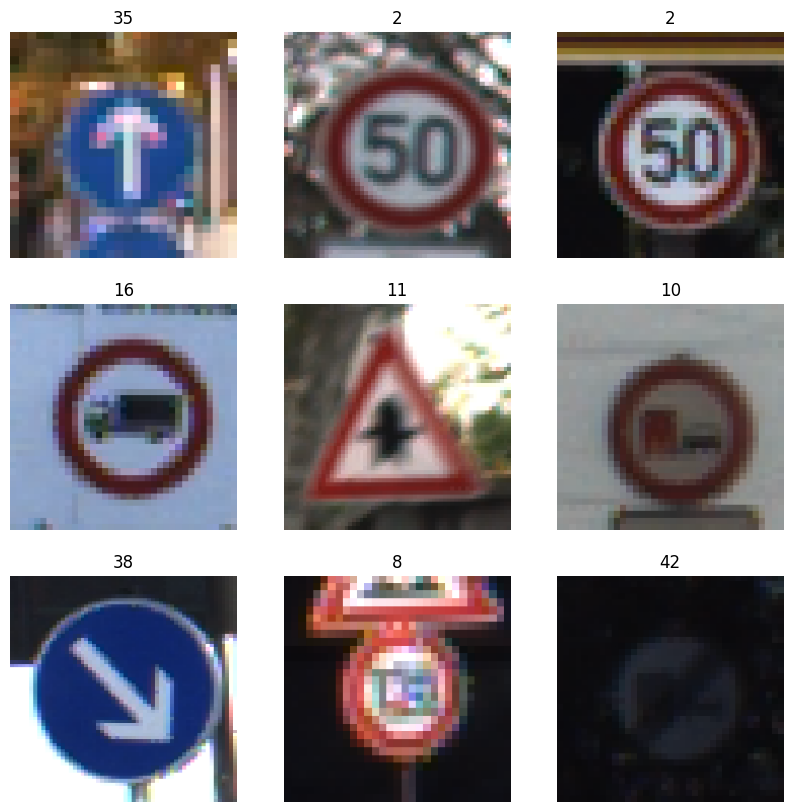

In [30]:
# ==============================
# PATHS
# ==============================
zip_path = "/content/gtsrb-german-traffic-sign.zip"
extract_path = "/content/gtsrb"

# -------- UNZIP --------
if not os.path.exists(extract_path):
  with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# ==============================
# TRAIN DIR
# ==============================
train_dir = "/content/gtsrb/Train"

print("Train dir exists:", os.path.exists(train_dir))

# ==============================
# DATA GENERATOR
# ==============================
datagen = ImageDataGenerator(rescale=1./255)

train_gen = datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

# ==============================
# INFO
# ==============================
print("\nClasses:", train_gen.num_classes)
print("Samples:", train_gen.samples)
print("Class indices:", train_gen.class_indices)

# ==============================
# SHOW SAMPLES
# ==============================
x_batch, y_batch = next(train_gen)

labels = {v: k for k, v in train_gen.class_indices.items()}

plt.figure(figsize=(10,10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(x_batch[i])
    plt.title(labels[y_batch[i].argmax()])
    plt.axis('off')
plt.show()


## **Using MobileNet and VGG16 in TensorFlow (Keras)**


In [31]:
# ==============================
# MOBILE NET MODEL
# ==============================
base_model = MobileNet(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze base model
for layer in base_model.layers:
    layer.trainable = False

# Custom head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


history = model.fit(
    train_gen,
    epochs=15,
    steps_per_epoch=train_gen.samples // BATCH_SIZE
)

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 112, 112, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 112, 112, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 112, 112, 64)   │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 113, 113, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 56, 56, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 56, 56, 128)    │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 56, 56, 128)    │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 56, 56, 128)    │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3_bn                    │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 3,502,315 (13.36 MB)

 Trainable params: 273,451 (1.04 MB)

 Non-trainable params: 3,228,864 (12.32 MB)

Epoch 1/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 77s 52ms/step - accuracy: 0.7860 - loss: 0.7003
Epoch 2/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 0s 10us/step - accuracy: 0.7500 - loss: 0.5572 
Epoch 3/15
   3/1225 ━━━━━━━━━━━━━━━━━━━━ 46s 38ms/step - accuracy: 0.9149 - loss: 0.2891 

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1225/1225 ━━━━━━━━━━━━━━━━━━━━ 48s 39ms/step - accuracy: 0.9146 - loss: 0.2602
Epoch 4/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 0s 11us/step - accuracy: 0.9062 - loss: 0.2216 
Epoch 5/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 83s 40ms/step - accuracy: 0.9362 - loss: 0.1875
Epoch 6/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 0s 13us/step - accuracy: 0.9688 - loss: 0.1035 
Epoch 7/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 87s 45ms/step - accuracy: 0.9466 - loss: 0.1532
Epoch 8/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 0s 12us/step - accuracy: 0.9688 - loss: 0.0815 
Epoch 9/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 51s 42ms/step - accuracy: 0.9555 - loss: 0.1296
Epoch 10/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 0s 10us/step - accuracy: 0.9375 - loss: 0.1692 
Epoch 11/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 47s 38ms/step - accuracy: 0.9590 - loss: 0.1170
Epoch 12/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 0s 12us/step - accuracy: 0.9688 - loss: 0.0407 
Epoch 13/15
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 49s 40ms/step - accuracy: 0.9648 - loss: 0.0987
Epoch 14/15
1225/

In [32]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze base model
for layer in base_model.layers:
    layer.trainable = False

# Custom head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=outputs)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    train_gen,
    epochs=5,
    steps_per_epoch=train_gen.samples // BATCH_SIZE
)

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,857,067 (56.68 MB)

 Trainable params: 142,379 (556.17 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/5
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 252s 203ms/step - accuracy: 0.2794 - loss: 2.6213
Epoch 2/5
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 0s 12us/step - accuracy: 0.4375 - loss: 1.8608   
Epoch 3/5
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 248s 202ms/step - accuracy: 0.4286 - loss: 1.9775
Epoch 4/5
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 0s 13us/step - accuracy: 0.2500 - loss: 2.0126   
Epoch 5/5
1225/1225 ━━━━━━━━━━━━━━━━━━━━ 248s 202ms/step - accuracy: 0.4981 - loss: 1.7120


In [33]:
from tensorflow.keras.applications.mobilenet import preprocess_input as mobilenet_pre
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_pre

datagen = ImageDataGenerator(validation_split=0.2)

train_gen = datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

val_gen = datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)

Found 31368 images belonging to 43 classes.
Found 7841 images belonging to 43 classes.


In [34]:
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam, SGD

def build_model(base_model, num_classes, optimizer):

    for layer in base_model.layers:
        layer.trainable = False

    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=outputs)

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
from tensorflow.keras.applications import MobileNet, VGG16

results = []

# ================= MOBILE NET =================
mobilenet_model = build_model(
    MobileNet(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    NUM_CLASSES,
    Adam()
)

hist_mob = mobilenet_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

results.append({
    "Model": "MobileNet",
    "Train Acc": max(hist_mob.history['accuracy']),
    "Val Acc": max(hist_mob.history['val_accuracy']),
})

# ================= VGG16 =================
vgg_model = build_model(
    VGG16(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    NUM_CLASSES,
    Adam()
)

hist_vgg = vgg_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5
)

results.append({
    "Model": "VGG16",
    "Train Acc": max(hist_vgg.history['accuracy']),
    "Val Acc": max(hist_vgg.history['val_accuracy']),
})

Epoch 1/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 65s 60ms/step - accuracy: 0.4752 - loss: 1.7550 - val_accuracy: 0.4596 - val_loss: 1.7616
Epoch 2/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 49s 50ms/step - accuracy: 0.6262 - loss: 1.1492 - val_accuracy: 0.5168 - val_loss: 1.6706
Epoch 3/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 48s 49ms/step - accuracy: 0.6878 - loss: 0.9471 - val_accuracy: 0.5096 - val_loss: 1.6776
Epoch 4/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 49s 50ms/step - accuracy: 0.7231 - loss: 0.8334 - val_accuracy: 0.5045 - val_loss: 1.7611
Epoch 5/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 81s 49ms/step - accuracy: 0.7433 - loss: 0.7647 - val_accuracy: 0.5368 - val_loss: 1.6885
Epoch 6/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 48s 49ms/step - accuracy: 0.7677 - loss: 0.6890 - val_accuracy: 0.5474 - val_loss: 1.7539
Epoch 7/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 48s 49ms/step - accuracy: 0.7821 - loss: 0.6469 - val_accuracy: 0.5405 - val_loss: 1.8181
Epoch 8/10
981/981 ━━━━━━━━━━━━━━━━━━━━ 46s 47ms/step - accuracy: 0.7933 - loss: 0.5983 - 

In [36]:
df_models = pd.DataFrame(results)
print(df_models)

       Model  Train Acc   Val Acc
0  MobileNet   0.747035  0.539089
1      VGG16   0.844523  0.619819


In [37]:
opt_results = []

# Adam
model_adam = build_model(
    MobileNet(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    NUM_CLASSES,
    Adam(learning_rate=1e-3)
)

hist_adam = model_adam.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5
)

opt_results.append({
    "Optimizer": "Adam",
    "Train Acc": max(hist_adam.history['accuracy']),
    "Val Acc": max(hist_adam.history['val_accuracy']),
})

# SGD
model_sgd = build_model(
    MobileNet(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    NUM_CLASSES,
    SGD(learning_rate=0.01, momentum=0.9)
)

hist_sgd = model_sgd.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5
)

opt_results.append({
    "Optimizer": "SGD",
    "Train Acc": max(hist_sgd.history['accuracy']),
    "Val Acc": max(hist_sgd.history['val_accuracy']),
})

Epoch 1/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 62s 56ms/step - accuracy: 0.4715 - loss: 1.7670 - val_accuracy: 0.4743 - val_loss: 1.7402
Epoch 2/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 47s 48ms/step - accuracy: 0.6283 - loss: 1.1508 - val_accuracy: 0.5161 - val_loss: 1.6658
Epoch 3/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 45s 46ms/step - accuracy: 0.6810 - loss: 0.9666 - val_accuracy: 0.5180 - val_loss: 1.7046
Epoch 4/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 48s 49ms/step - accuracy: 0.7164 - loss: 0.8522 - val_accuracy: 0.5339 - val_loss: 1.6550
Epoch 5/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 49s 50ms/step - accuracy: 0.7416 - loss: 0.7759 - val_accuracy: 0.5368 - val_loss: 1.6842
Epoch 1/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 65s 61ms/step - accuracy: 0.3431 - loss: 2.1496 - val_accuracy: 0.3831 - val_loss: 2.0411
Epoch 2/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 47s 48ms/step - accuracy: 0.4395 - loss: 1.7472 - val_accuracy: 0.4332 - val_loss: 1.9302
Epoch 3/5
981/981 ━━━━━━━━━━━━━━━━━━━━ 46s 47ms/step - accuracy: 0.4621 - loss: 1.6521 - val_accu

In [38]:
df_opt = pd.DataFrame(opt_results)
print(df_opt)

  Optimizer  Train Acc   Val Acc
0      Adam   0.741616  0.536794
1       SGD   0.506185  0.465502


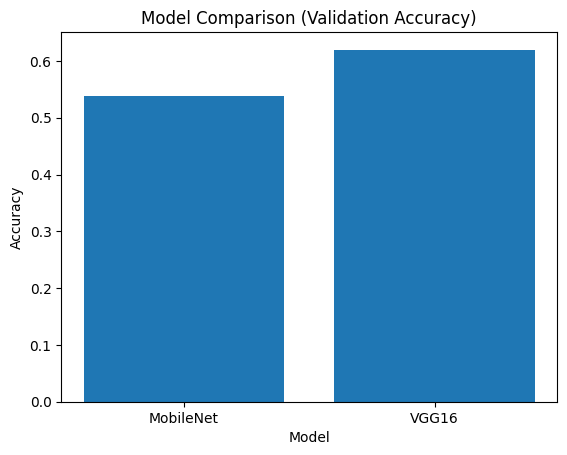

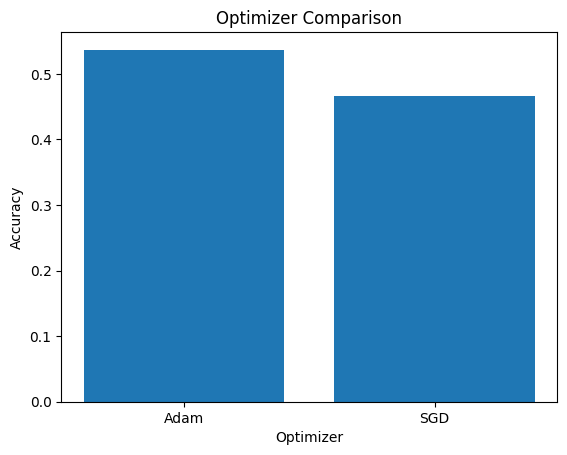

In [39]:
# Transfer Learning Plot
plt.figure()
plt.bar(df_models["Model"], df_models["Val Acc"])
plt.title("Model Comparison (Validation Accuracy)")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.show()

# Optimizer Plot
plt.figure()
plt.bar(df_opt["Optimizer"], df_opt["Val Acc"])
plt.title("Optimizer Comparison")
plt.xlabel("Optimizer")
plt.ylabel("Accuracy")
plt.show()